## 0. Imports and loading previously organized spike/event arrays

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.stats import pearsonr, zscore, false_discovery_control
from scipy.linalg import eigh, svd, orth
from scipy.ndimage import gaussian_filter1d
from scipy.spatial.distance import pdist
from sklearn.model_selection import LeaveOneGroupOut
from fitting import svd_RRR # Semedo et al., 2019; https://github.com/bichanw/RRR

INPUT_PATH = Path('./results/Data.npz')
FIG_DIR = Path('./figures_cs')
FIG_DIR.mkdir(exist_ok=True)
PARTICIPANTS = ['YFF', 'YFI', 'YFJ', 'YFK', 'YFL', 'YFM', 'YFR', 'YFS', 'YFT', 'YFU']
REGIONS = ['acc', 'amy', 'ent', 'hpc', 'ofc', 'para-hpc', 'thal']
NUM_GROUPS = [[n] for n in range(1, 11)]
CS_SUBJECT_INDICES = [6, 7, 8, 9]
CS_NAMES = [PARTICIPANTS[s] for s in CS_SUBJECT_INDICES]
HPC_INDEX, AMY_INDEX = 3, 1
BIN_MS, N_BINS, SMOOTH_MS = 35, 100, 100
LAMBDA_GRID = np.logspace(1, 10, 20)
N_PRED_PERM = 1000
N_NUM_PERM = 1000
N_K_PERM = 1000
N_PC_PERM = 1000
N_EPOCH_PERM = 100
SEED = 2026

In [ ]:
EVENT_KEYS = ('presen_start','presen_end','resp_start','resp_end','dot_num','correct','error')
with np.load(INPUT_PATH, allow_pickle=False) as archive:
    meta = json.loads(str(archive['metadata_json'].item()))
    assert meta['schema'] == 'figure5-organized-inputs-v1'
    assert meta['participants'] == PARTICIPANTS
    assert meta['regions'] == REGIONS
    assert meta['event_keys'] == list(EVENT_KEYS)
    spikes = [archive[f'spikes_{i}'].copy() for i in range(len(PARTICIPANTS))]
    labels = [archive[f'labels_{i}'].astype(str) for i in range(len(PARTICIPANTS))]
    event_logs = [
        {k: archive[f'event_{i}_{k}'].copy() for k in EVENT_KEYS}
        for i in range(len(PARTICIPANTS))
    ]

for i, name in enumerate(PARTICIPANTS):
    assert spikes[i].ndim == 2 and spikes[i].shape[0] == len(labels[i]), name
    ntrials = len(event_logs[i]['dot_num'])
    assert all(len(event_logs[i][key]) == ntrials for key in EVENT_KEYS), name
    print(f'{name}: {spikes[i].shape[0]} neurons, {ntrials} trials')

labels_concat = np.concatenate(labels)
trial_idx = [[np.concatenate([np.where(event_logs[s]['dot_num'] == num)[0]
                              for num in NUM_GROUPS[n]])
              for n in range(len(NUM_GROUPS))]
             for s in range(len(event_logs))]
region_idx = [np.where(labels_concat == r)[0] for r in REGIONS]
region_indices = [[np.where(labels[s] == r)[0] for r in REGIONS]
                  for s in range(len(event_logs))]
neuron_idx = [spikes[s].shape[0] for s in range(len(event_logs))]
neuron_idx_cumsum = np.concatenate([[0], np.cumsum(neuron_idx)])


YFF: 54 neurons, 112 trials
YFI: 38 neurons, 64 trials
YFJ: 62 neurons, 164 trials
YFK: 68 neurons, 160 trials
YFL: 94 neurons, 119 trials
YFM: 94 neurons, 160 trials
YFR: 78 neurons, 300 trials
YFS: 96 neurons, 300 trials
YFT: 89 neurons, 300 trials
YFU: 79 neurons, 300 trials


In [ ]:
def trial_wise_avg(spikes, roi, event_log, trial_idx, locked='presen_start', delay=0, bin_time=40, bin_num=50, smooth_ms = None):
    L = bin_num * bin_time
    scale = 1000.0 / bin_time
    ev = np.asarray(event_log[locked], dtype=np.int64) + delay
    C, T = spikes[roi].shape
    sp = spikes[roi]

    need = int(ev.max()) + L - T
    if need > 0:
        sp = np.pad(sp, ((0, 0), (0, need)))

    binned = np.empty((C, len(ev), bin_num), dtype=np.float32)
    arange_bt = np.arange(bin_time)
    for b in range(bin_num):
        idx = (ev + b * bin_time)[:, None] + arange_bt   # (E, bin_time)
        binned[:, :, b] = sp[:, idx].sum(axis=-1)
    binned *= scale
    trials = binned.transpose(1, 2, 0) 

    trial_avg = []
    for c in range(len(trial_idx)):
        trial_avg.append(trials[trial_idx[c]].mean(axis=0))
    trial_avg = np.array(trial_avg)
    
    if smooth_ms == None:
        return trial_avg
    else:
        return gaussian_filter1d(trial_avg, sigma=smooth_ms/bin_time, axis=1, mode='nearest')
    
def trial_wise_signal(spikes, roi, event_log, trial_idx, locked='presen_start', delay=0, bin_time=40, bin_num=50, smooth_ms = None):
    L = bin_num * bin_time
    scale = 1000.0 / bin_time
    ev = np.asarray(event_log[locked], dtype=np.int64) + delay
    C, T = spikes[roi].shape
    sp = spikes[roi]

    need = int(ev.max()) + L - T
    if need > 0:
        sp = np.pad(sp, ((0, 0), (0, need)))

    binned = np.empty((C, len(ev), bin_num), dtype=np.float32)
    arange_bt = np.arange(bin_time)
    for b in range(bin_num):
        idx = (ev + b * bin_time)[:, None] + arange_bt   # (E, bin_time)
        binned[:, :, b] = sp[:, idx].sum(axis=-1)
    binned *= scale
    trials = binned.transpose(1, 2, 0) 

    if smooth_ms == None:
        return trials
    else:
        return gaussian_filter1d(trials, sigma=smooth_ms/bin_time, axis=1, mode='nearest')
    
def trial_wise_noise(spikes, roi, event_log, trial_idx, locked='presen_start', delay=0, bin_time=40, bin_num=50, smooth_ms = None):
    L = bin_num * bin_time
    scale = 1000.0 / bin_time
    ev = np.asarray(event_log[locked], dtype=np.int64) + delay
    C, T = spikes[roi].shape
    sp = spikes[roi]

    need = int(ev.max()) + L - T
    if need > 0:
        sp = np.pad(sp, ((0, 0), (0, need)))

    binned = np.empty((C, len(ev), bin_num), dtype=np.float32)
    arange_bt = np.arange(bin_time)
    for b in range(bin_num):
        idx = (ev + b * bin_time)[:, None] + arange_bt   # (E, bin_time)
        binned[:, :, b] = sp[:, idx].sum(axis=-1)
    binned *= scale
    trials = binned.transpose(1, 2, 0) 
    
    for c in range(len(trial_idx)):
        trial_avg = trials[trial_idx[c]].mean(axis=0)
        trials[trial_idx[c]] = trials[trial_idx[c]] - trial_avg

    if smooth_ms == None:
        return trials
    else:
        return gaussian_filter1d(trials, sigma=smooth_ms/bin_time, axis=1, mode='nearest')

def condition_wise_avg(spikes, trial_idx, roi, event_logs, locked='presen_start', delay=0, bin_time=40, bin_num=50, smooth_ms = 100):
    L = bin_num * bin_time
    scale = 1000.0 / bin_time
    conds = []

    for s in range(len(event_logs)):
        ev = np.asarray(event_logs[s][locked], dtype=np.int64) + delay
        C, T = spikes[s].shape
        sp = spikes[s]

        need = int(ev.max()) + L - T
        if need > 0:
            sp = np.pad(sp, ((0, 0), (0, need)))

        binned = np.empty((C, len(ev), bin_num), dtype=np.float32)
        arange_bt = np.arange(bin_time)
        for b in range(bin_num):
            idx = (ev + b * bin_time)[:, None] + arange_bt   # (E, bin_time)
            binned[:, :, b] = sp[:, idx].sum(axis=-1)
        binned *= scale

        trials = binned.transpose(1, 2, 0)                   # (E, bin_num, C)
        trial_avg = [trials[trial_idx[s][c]].mean(axis=0) for c in range(len(trial_idx[s]))]
        conds.append(np.array(trial_avg))                    # (num_conds, bin_num, C)

    conds = np.concatenate(conds, axis=2)                    # (num_conds, bin_num, total_C)
    # roi만 먼저 자르고 smoothing → 연산량 축소
    return gaussian_filter1d(conds[:, :, roi], sigma=smooth_ms/bin_time, axis=1, mode='nearest')

## 1. Rank-2 residual RRR, cross-validated prediction, and model rank (Fig. 5B–C)

In [ ]:
def noise_RRR_cv_entire(reg1, reg2, n_folds = 5, rand = None):
    if rand != None:
        np.random.seed(rand)
    
    data1 = reg1
    if rand == None:
        data2 = reg2
    else:
        data2 = reg2[np.random.permutation(np.arange(len(reg1)))]

    X = data1.reshape(-1, data1.shape[-1])
    Y = data2.reshape(-1, data2.shape[-1])

    trial_num = data1.shape[0]
    bin_num = data1.shape[1]

    ranks_to_test   = np.arange(1, np.min([data1.shape[-1], data2.shape[-1]]))
    lambdas_to_test = np.logspace(1, 10, 20) 

    trial_groups = np.repeat(np.arange(trial_num) * n_folds // trial_num, bin_num)  
    logo = LeaveOneGroupOut()
    n_folds = logo.get_n_splits(groups=trial_groups)

    cv_r2 = np.zeros((n_folds, len(ranks_to_test), len(lambdas_to_test)))
    for fold_idx, (train_idx, test_idx) in enumerate(logo.split(X, Y, groups=trial_groups)):
        X_train, X_test = X[train_idx], X[test_idx]
        Y_train, Y_test = Y[train_idx], Y[test_idx]

        X_train_c = X_train - X_train.mean(axis=0)
        X_test_c  = X_test  - X_test.mean(axis=0)
        Y_train_c = Y_train - Y_train.mean(axis=0)
        Y_test_c  = Y_test  - Y_test.mean(axis=0)

        ss_tot = np.sum(Y_test_c ** 2)
        for l_idx, lam in enumerate(lambdas_to_test): 
            for r_idx, rnk in enumerate(ranks_to_test):
                W_hat = svd_RRR(X_train_c, Y_train_c, rnk, lam)[0]
                Y_pred = X_test_c @ W_hat
                ss_res = np.sum((Y_test_c - Y_pred) ** 2)
                cv_r2[fold_idx, r_idx, l_idx] = 1.0 - ss_res / ss_tot
    mean_r2 = cv_r2.mean(axis=0)
    sem = cv_r2.std(axis=0)/np.sqrt(n_folds)
    return mean_r2, sem

def noise_RRR(reg1, reg2, rnk, lam, n_folds = 5):
    data1 = reg1
    data2 = reg2

    X = data1.reshape(-1, data1.shape[-1])
    Y = data2.reshape(-1, data2.shape[-1])

    trial_num = data1.shape[0]
    bin_num = data1.shape[1]

    lambdas_to_test = np.logspace(1, 10, 20) 

    trial_groups = np.repeat(np.arange(trial_num) * n_folds // trial_num, bin_num)  
    logo = LeaveOneGroupOut()
    n_folds = logo.get_n_splits(groups=trial_groups)

    cv_r2 = []
    for _, (train_idx, test_idx) in enumerate(logo.split(X, Y, groups=trial_groups)):
        X_train, X_test = X[train_idx], X[test_idx]
        Y_train, Y_test = Y[train_idx], Y[test_idx]

        X_train_c = X_train - X_train.mean(axis=0)
        X_test_c  = X_test  - X_test.mean(axis=0)
        Y_train_c = Y_train - Y_train.mean(axis=0)
        Y_test_c  = Y_test  - Y_test.mean(axis=0)

        ss_tot = np.sum(Y_test_c ** 2)
        W_hat = svd_RRR(X_train_c, Y_train_c, rnk, lam)[0]
        Y_pred = X_test_c @ W_hat
        ss_res = np.sum((Y_test_c - Y_pred) ** 2)
        cv_r2.append(1.0 - ss_res / ss_tot)
    mean_r2 = np.mean(cv_r2)
    sem = np.std(cv_r2)/np.sqrt(n_folds)
    return mean_r2, sem

In [ ]:
def residual_pair(subj, delay=0, n_bins=N_BINS):
    reg_h = trial_wise_noise(spikes[subj], region_indices[subj][HPC_INDEX],
                             event_logs[subj], trial_idx[subj], locked='presen_start',
                             delay=delay, bin_time=BIN_MS, bin_num=n_bins, smooth_ms=SMOOTH_MS)
    reg_a = trial_wise_noise(spikes[subj], region_indices[subj][AMY_INDEX],
                             event_logs[subj], trial_idx[subj], locked='presen_start',
                             delay=delay, bin_time=BIN_MS, bin_num=n_bins, smooth_ms=SMOOTH_MS)
    return reg_h, reg_a

def mean_pair(subj, delay=0, n_bins=N_BINS):
    reg_h = trial_wise_avg(spikes[subj], region_indices[subj][HPC_INDEX],
                           event_logs[subj], trial_idx[subj], locked='presen_start',
                           delay=delay, bin_time=BIN_MS, bin_num=n_bins, smooth_ms=SMOOTH_MS)
    reg_a = trial_wise_avg(spikes[subj], region_indices[subj][AMY_INDEX],
                           event_logs[subj], trial_idx[subj], locked='presen_start',
                           delay=delay, bin_time=BIN_MS, bin_num=n_bins, smooth_ms=SMOOTH_MS)
    return reg_h, reg_a

cs_residuals = {s: residual_pair(s) for s in CS_SUBJECT_INDICES}
cv_results, cv_best_lambda_idx, cv_best_rank = [], [], []
for s in CS_SUBJECT_INDICES:
    X, Y = cs_residuals[s]
    cv_grid, _ = noise_RRR_cv_entire(X, Y, n_folds=5)
    best_rank_idx, best_lam_idx = np.unravel_index(np.argmax(cv_grid), cv_grid.shape)
    cv_results.append(cv_grid)
    cv_best_lambda_idx.append(int(best_lam_idx))
    cv_best_rank.append(int(best_rank_idx + 1))
    print(PARTICIPANTS[s], 'best raw CV rank', best_rank_idx+1,
          'lambda', LAMBDA_GRID[best_lam_idx],
          'rank-2 CV R2', cv_grid[1, best_lam_idx])

YFR best raw CV rank 15 lambda 545559.4781168514 rank-2 CV R2 0.007305927535824042
YFS best raw CV rank 2 lambda 183298.07108324338 rank-2 CV R2 0.06790447884028242
YFT best raw CV rank 2 lambda 6951.927961775606 rank-2 CV R2 0.04195515891583601
YFU best raw CV rank 5 lambda 1623776.739188721 rank-2 CV R2 0.0037638467009528443


In [12]:
vis_order = np.array([1,2,0,3])

rng = np.random.default_rng(SEED)
observed_rank2 = np.array([grid[1, idx] for grid, idx in zip(cv_results, cv_best_lambda_idx)])
null_rank2 = np.empty((len(CS_SUBJECT_INDICES), N_PRED_PERM))
for i, s in enumerate(CS_SUBJECT_INDICES):
    X, Y = cs_residuals[s]
    for permutation in range(N_PRED_PERM):
        # Trial identities shuffled; each trial's time course stays intact.
        shuffled_trials = rng.permutation(len(Y))
        null_rank2[i, permutation], _ = noise_RRR(
            X, Y[shuffled_trials], rnk=2, lam=LAMBDA_GRID[cv_best_lambda_idx[i]], n_folds=5)
chance95 = np.quantile(null_rank2, 0.95, axis=1)

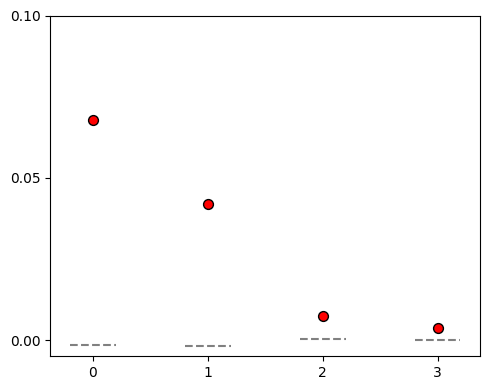

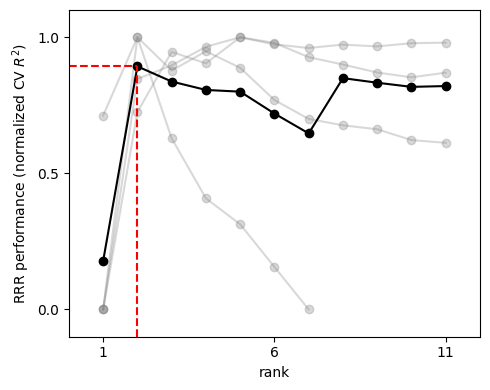

In [128]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(np.arange(4), observed_rank2[vis_order], s=50, color='red', edgecolors='k')
for i, level in enumerate(chance95[vis_order]):
    ax.hlines(level, i-0.2, i+0.2, color='grey', linestyle='--')
ax.set_xticks([0, 1, 2, 3])
ax.set_yticks([0, 0.05, 0.1])
ax.set_ylim([-0.005, 0.1])
fig.tight_layout()
fig.savefig(FIG_DIR/'Figure5B.png', dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
normalized_cv = []
for r2, lam_idx in zip(cv_results, cv_best_lambda_idx):
    values = r2[:, lam_idx]
    vmin, vmax = np.nanmin(values), np.nanmax(values)
    scaled = (values-vmin)/(vmax-vmin) if vmax > vmin else np.full_like(values, np.nan)
    normalized_cv.append(scaled)
    ax.plot(np.arange(1,np.min([len(scaled), 11])+1), scaled[:11], 'o-', color='grey', alpha=0.3)
max_rank = max(len(v) for v in normalized_cv)
mean_curve = [np.nanmean([v[r] for v in normalized_cv if len(v)>r]) for r in range(max_rank)]

ax.plot(np.arange(1, min(max_rank, 11)+1), mean_curve[:11], 'o-', color='k')
ax.vlines(2, -0.1, mean_curve[1], linestyle='--', color='red')
ax.hlines(mean_curve[1], 0, 2, linestyle='--', color='red')
ax.set_xticks([1, 6, 11])
ax.set_xlim([0, 12])
ax.set_yticks([0, 0.5, 1])
ax.set_ylim([-0.1, 1.1])
ax.set_xlabel('rank')
ax.set_ylabel('RRR performance (normalized CV $R^2$)')
fig.tight_layout()
fig.savefig(FIG_DIR/'Figure5C.png', dpi=300)
plt.show()

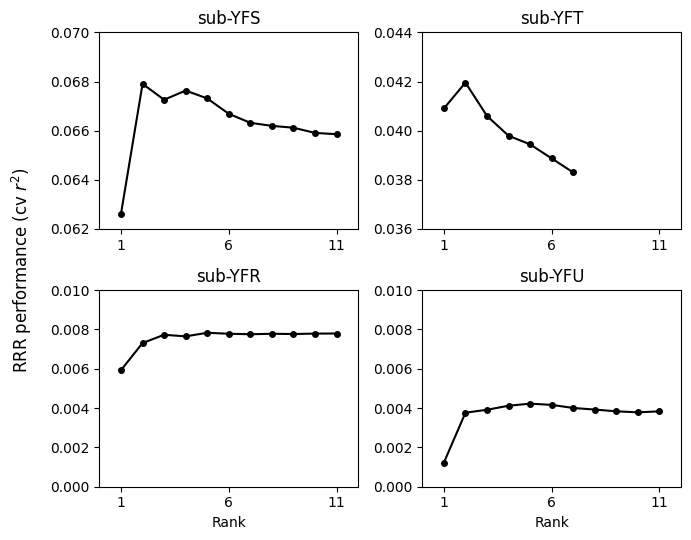

In [119]:
SUBJ_NAMES = ['sub-YFS', 'sub-YFT', 'sub-YFR', 'sub-YFU']   # cv_results 순서와 맞출 것
YLIMS = [(0.062, 0.070), (0.036, 0.044), (0, 0.01), (0, 0.01)]
vis_order = [1,2,0,3]

fig, axes = plt.subplots(2, 2, figsize=(7, 5.5))
for k, ax in enumerate(axes.flat):
    v = cv_results[vis_order[k]][:11, cv_best_lambda_idx[vis_order[k]]]
    ax.plot(np.arange(1, len(v)+1), v, 'o-', color='k', markersize=4)
    ax.set_xticks([1, 6, 11])
    ax.set_xlim([0, 12])
    ax.set_ylim(YLIMS[k])
    ax.set_title(SUBJ_NAMES[k])

for ax in axes[1]:
    ax.set_xlabel('Rank')
fig.supylabel('RRR performance (cv $r^2$)')
fig.tight_layout()
fig.savefig(FIG_DIR/'FigureS3A.png', dpi=300)
plt.show()

## 2. Communication-space numerosity projection, dynamics, and decoding (Fig. 5D–E)

In [48]:
def project_communication_responses(subj, lambda_idx):
    reg_h, reg_a = cs_residuals[subj]
    X = reg_h.reshape(-1, reg_h.shape[-1]); X = X - X.mean(axis=0)
    Y = reg_a.reshape(-1, reg_a.shape[-1]); Y = Y - Y.mean(axis=0)
    W, U, V = svd_RRR(X, Y, 2, LAMBDA_GRID[lambda_idx])
    mean_h, mean_a = mean_pair(subj)
    return mean_h @ U, mean_a @ V.T, W, U, V

projections_hpc, projections_amy, models_rrr = [], [], []
for i, s in enumerate(CS_SUBJECT_INDICES):
    P_h, P_a, W, U, V = project_communication_responses(s, cv_best_lambda_idx[i])
    projections_hpc.append(P_h)
    projections_amy.append(P_a)
    models_rrr.append((W, U, V))
assert all(p.shape[:2] == (10,N_BINS) for p in projections_hpc + projections_amy)

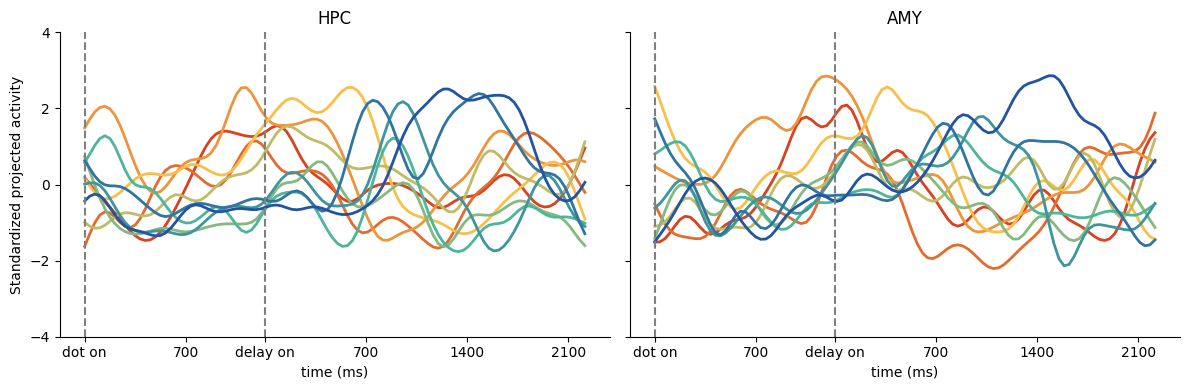

In [120]:
dot_colors = [mcolors.to_hex(mcolors.LinearSegmentedColormap.from_list(
    'dots', ['#D94220','#F7BF4B','#4DB69A','#2354A1'])(t/9)) for t in range(10)]
example_subject = 1  # YFS, as in source example
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, proj, label, snapshot in [(axes[0], projections_hpc[example_subject], 'HPC', 25),
                                  (axes[1], projections_amy[example_subject], 'AMY', 36)]:
    trajectories = zscore(proj[:,:,0], axis=None)
    for n in range(10):
        ax.plot(np.arange(N_BINS)*BIN_MS, trajectories[n], color=dot_colors[n], linewidth=2)
    ax.set_xticks([0, 700, 1250, 1950, 2650, 3350],
                  ['dot on', 700, 'delay on', 700, 1400, 2100])
    ax.vlines([0, 1250], -4, 4, color='grey', linestyle='--')
    ax.set_yticks([-4, -2, 0, 2, 4])
    ax.set_ylim([-4, 4])
    ax.set_title(label)
    ax.set_xlabel('time (ms)')
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
axes[0].set_ylabel('Standardized projected activity')
fig.tight_layout()
fig.savefig(FIG_DIR/'Figure5D.png', dpi=300)
plt.show()

In [51]:
def r2_subspace(P, labels=np.arange(1,11)):
    y = labels - labels.mean()
    out = np.zeros(P.shape[1])
    w = np.zeros((P.shape[1], P.shape[2]))
    for t in range(P.shape[1]):
        A = P[:, t, :] - P[:, t, :].mean(0)
        beta, *_ = np.linalg.lstsq(A, y, rcond=None)
        pred = A @ beta
        out[t] = 1 - np.sum((y - pred)**2) / np.sum(y**2)
        w[t] = beta
    return out, w

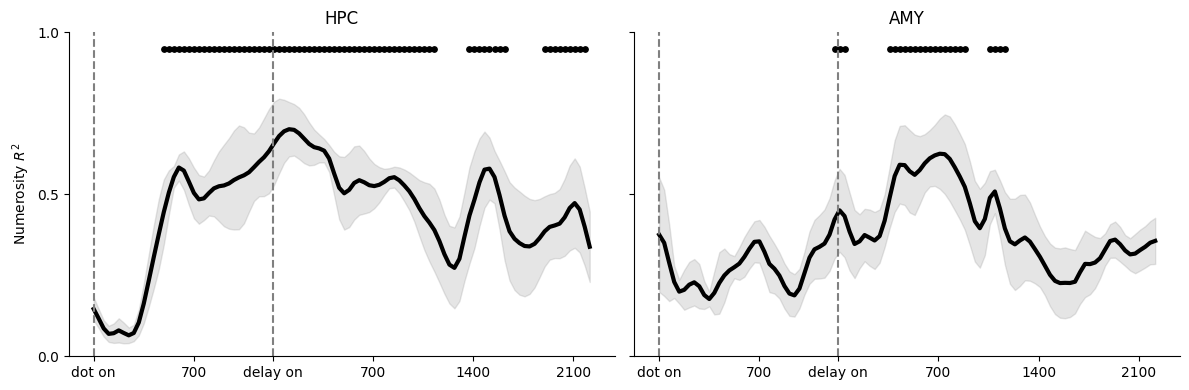

In [121]:
labels = np.arange(1, 11)
observed_hpc = np.array([r2_subspace(p, labels)[0] for p in projections_hpc])
observed_amy = np.array([r2_subspace(p, labels)[0] for p in projections_amy])
null_hpc = np.empty((N_NUM_PERM, 4, N_BINS))
null_amy = np.empty((N_NUM_PERM, 4, N_BINS))
rng = np.random.default_rng(SEED)
for b in range(N_NUM_PERM):
    shuffled_labels = rng.permutation(labels)
    for i in range(4):
        null_hpc[b,i] = r2_subspace(projections_hpc[i], shuffled_labels)[0]
        null_amy[b,i] = r2_subspace(projections_amy[i], shuffled_labels)[0]

def perm_fdr(null, observed):
    p = (1 + np.sum(np.mean(null,axis=1) > np.mean(observed,axis=0),axis=0)) / (len(null)+1)
    return false_discovery_control(p, method='bh')
q_hpc = perm_fdr(null_hpc, observed_hpc)
q_amy = perm_fdr(null_amy, observed_amy)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, values, q, label in [(axes[0],observed_hpc,q_hpc,'HPC'),(axes[1],observed_amy,q_amy,'AMY')]:
    x = np.arange(N_BINS)*BIN_MS
    ax.plot(x, values.mean(axis=0), color='k', linewidth=3)
    ax.fill_between(x, values.mean(axis=0)-values.std(axis=0)/np.sqrt(4),
                       values.mean(axis=0)+values.std(axis=0)/np.sqrt(4), color='grey', alpha=0.2)
    ax.scatter(x[q < .05], np.full(np.sum(q < .05), .95), color='k', s=15)
    ax.set_xticks([0, 700, 1250, 1950, 2650, 3350],
                  ['dot on', 700, 'delay on', 700, 1400, 2100])
    ax.vlines([0, 1250], 0, 1, color='grey', linestyle='--')
    ax.set_yticks([0, 0.5, 1])
    ax.set_ylim([0, 1])
    ax.set_title(label)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
axes[0].set_ylabel('Numerosity $R^2$')
fig.tight_layout()
fig.savefig(FIG_DIR/'Figure5E.png', dpi=300)
plt.show()

## 3. Dynamic k-individuation geometry (Fig. 5F)

In [ ]:
K_VALUES = np.arange(4,10)
MODEL_RDMS = []
for k in K_VALUES:
    effective = np.where(labels<=k,labels,k+1)
    model = np.abs(effective[:,None]-effective[None,:]).astype(float)
    MODEL_RDMS.append(model/model.max())
TRIU = np.triu_indices(10,k=1)
MODEL_VECTORS = np.array([m[TRIU] for m in MODEL_RDMS])

def mean_neural_rdm(projected_list):
    return np.array([np.mean([pdist(projected[:,t,:],metric='euclidean')
                              for projected in projected_list],axis=0)
                     for t in range(N_BINS)])

def rdm_r2(neural, model):
    model = np.asarray(model)
    neural = np.asarray(neural)
    design = np.column_stack([model, np.ones(len(model))])
    fit = design @ np.linalg.lstsq(design, neural, rcond=None)[0]
    tot = np.sum((neural-neural.mean())**2)
    return 1 - np.sum((neural-fit)**2)/tot if tot > 0 else np.nan

rdm_hpc = mean_neural_rdm(projections_hpc)
rdm_amy = mean_neural_rdm(projections_amy)
model_r2_hpc = np.array([[rdm_r2(r,model) for model in MODEL_VECTORS] for r in rdm_hpc])
model_r2_amy = np.array([[rdm_r2(r,model) for model in MODEL_VECTORS] for r in rdm_amy])

rng = np.random.default_rng(SEED)
null_k_hpc = np.empty((N_K_PERM,N_BINS,len(K_VALUES)))
null_k_amy = np.empty_like(null_k_hpc)
for b in range(N_K_PERM):
    p = rng.permutation(10)
    shuffled_models = [m[np.ix_(p,p)][TRIU] for m in MODEL_RDMS]
    for t in range(N_BINS):
        null_k_hpc[b,t] = [rdm_r2(rdm_hpc[t],m) for m in shuffled_models]
        null_k_amy[b,t] = [rdm_r2(rdm_amy[t],m) for m in shuffled_models]

p_k_hpc = (1 + np.sum(null_k_hpc > model_r2_hpc[None,:,:],axis=0)) / (N_K_PERM+1)
p_k_amy = (1 + np.sum(null_k_amy > model_r2_amy[None,:,:],axis=0)) / (N_K_PERM+1)

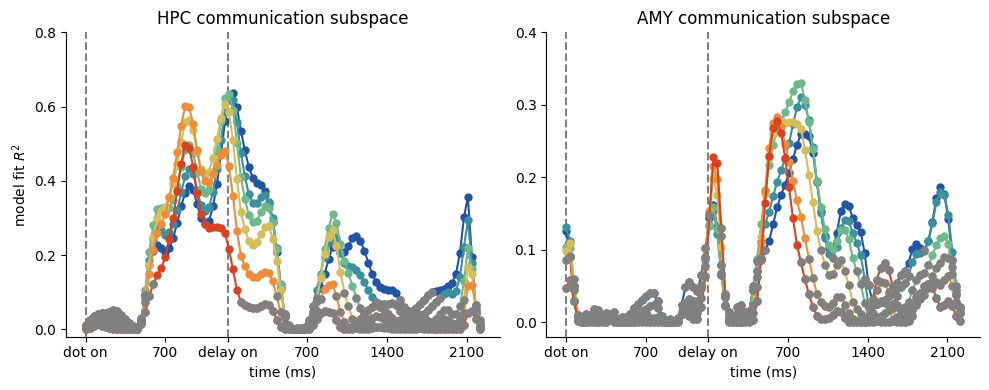

In [122]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, curves, pvals, title in [(axes[0],model_r2_hpc,p_k_hpc,'HPC'),
                                 (axes[1],model_r2_amy,p_k_amy,'AMY')]:
    xx = np.arange(N_BINS)*BIN_MS
    for j,k in enumerate(K_VALUES):
        color=mcolors.to_hex(mcolors.LinearSegmentedColormap.from_list(
            'k', ['#D94220','#F7BF4B','#4DB69A','#2354A1'])(j/5))
        ax.plot(xx, curves[:,j], 'o-', color=color, zorder=7-j, markersize=5)
        ns = pvals[:,j]>=.05
        ax.plot(xx[ns], curves[ns,j], 'o', color='grey', markersize=5, zorder=8)
    ax.set_xticks([0, 700, 1250, 1950, 2650, 3350],
                  ['dot on', 700, 'delay on', 700, 1400, 2100])
    ax.vlines([0, 1250], -0.02, 0.8, color='grey', linestyle='--', zorder=0)
    ax.set_title(f'{title} communication subspace')
    ax.set_xlabel('time (ms)')
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
axes[0].set_ylabel('model fit $R^2$')
axes[0].set_yticks([0, 0.2, 0.4, 0.6, 0.8])
axes[0].set_ylim([-0.02, 0.8])
axes[1].set_yticks([0, 0.1, 0.2, 0.3, 0.4])
axes[1].set_ylim([-0.02, 0.4])   
fig.tight_layout()
fig.savefig(FIG_DIR/'Figure5F.png', dpi=300)
plt.show()

## 4. Epoch-specific RRR rank and orientation (Figure S3B)

In [ ]:
def _subspace_alignment(U_comm, U_task):
    U_task = orth(U_task)                     
    M = U_comm.T @ U_task                    
    cos_ang = np.clip(svd(M, compute_uv=False), 0.0, 1.0)
    angles_deg = np.degrees(np.arccos(cos_ang))
    denom = min(U_comm.shape[1], U_task.shape[1])
    return cos_ang   # [0,1]

In [71]:
EPOCHS={'Dot on period':0,'Resp on period':1750}
epoch_ranks={};epoch_lambdas={};epoch_data={}
for epoch,start in EPOCHS.items():
    epoch_ranks[epoch]=[]
    epoch_lambdas[epoch]=[]
    for i,s in enumerate(CS_SUBJECT_INDICES):
        X,Y=residual_pair(s,delay=start,n_bins=50)
        epoch_data[(epoch,s)]=(X,Y)
        grid,_=noise_RRR_cv_entire(X,Y,n_folds=5)
        _,li=np.unravel_index(np.argmax(grid),grid.shape)
        epoch_ranks[epoch].append(grid)
        epoch_lambdas[epoch].append(li)

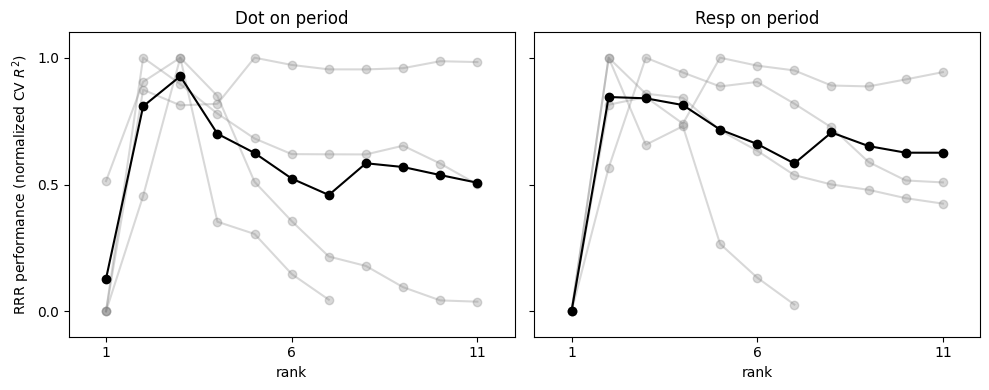

In [123]:
MAX_RANK = 11

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (epoch, grids) in zip(axes, epoch_ranks.items()):
    curves = []
    for grid, li in zip(grids, epoch_lambdas[epoch]):
        v = grid[:, li]
        v = (v - v.min()) / (v.max() - v.min())  
        v = v[:MAX_RANK]                        
        curves.append(v)
        ax.plot(np.arange(1, len(v)+1), v, 'o-', color='grey', alpha=0.3)

    n = max(map(len, curves))
    mean = [np.mean([v[i] for v in curves if i < len(v)]) for i in range(n)]
    ax.plot(np.arange(1, n+1), mean, 'o-', color='k')

    ax.set_xticks([1, 6, 11])
    ax.set_xlim([0, 12])
    ax.set_yticks([0, 0.5, 1])
    ax.set_ylim([-0.1, 1.1])
    ax.set_xlabel('rank')
    ax.set_title(epoch)

axes[0].set_ylabel('RRR performance (normalized CV $R^2$)')
fig.tight_layout()
fig.savefig(FIG_DIR/'FigureS3B.png', dpi=300)
plt.show()

In [ ]:
RANK = {'Dot on period': 2, 'Resp on period': 2}

def rrr_space(X, Y, lam, rank):
    xc = X.reshape(-1, X.shape[-1]); xc = xc - xc.mean(0)
    yc = Y.reshape(-1, Y.shape[-1]); yc = yc - yc.mean(0)
    W = svd_RRR(xc, yc, rank, lam)[0]
    u, _, vh = svd(W, full_matrices=False)
    return u[:, :rank], vh[:rank, :].T      

def alignment(Xd, Yd, lam_d, Xr, Yr, lam_r):
    Us_d, Ut_d = rrr_space(Xd, Yd, lam_d, RANK['Dot on period'])
    Us_r, Ut_r = rrr_space(Xr, Yr, lam_r, RANK['Resp on period'])
    return np.array([_subspace_alignment(Us_d, Us_r)[0],
                     _subspace_alignment(Ut_d, Ut_r)[0]]) 

rng = np.random.default_rng(SEED)
epoch_orientation = {}
for i, s in enumerate(CS_SUBJECT_INDICES):
    Xd, Yd = epoch_data[('Dot on period', s)]
    Xr, Yr = epoch_data[('Resp on period', s)]
    lam_d = LAMBDA_GRID[epoch_lambdas['Dot on period'][i]]
    lam_r = LAMBDA_GRID[epoch_lambdas['Resp on period'][i]]

    observed = alignment(Xd, Yd, lam_d, Xr, Yr, lam_r)

    null = np.empty((N_EPOCH_PERM, 2))
    for b in range(N_EPOCH_PERM):
        perm = rng.permutation(len(Yd))
        null[b] = alignment(Xd, Yd[perm], lam_d, Xr, Yr[perm], lam_r)

    p = (1 + (null >= observed).sum(0)) / (1 + N_EPOCH_PERM)
    epoch_orientation[s] = (observed, null)
    print(f'subject {s} | source: obs={observed[0]:.3f}, null 95%={np.percentile(null[:,0],95):.3f}, p={p[0]:.3f}'
          f' | target: obs={observed[1]:.3f}, null 95%={np.percentile(null[:,1],95):.3f}, p={p[1]:.3f}')

subject 6 | source: obs=0.605, null 95%=0.490, p=0.020 | target: obs=0.962, null 95%=0.980, p=0.366
subject 7 | source: obs=0.896, null 95%=0.505, p=0.010 | target: obs=0.987, null 95%=0.960, p=0.010
subject 8 | source: obs=0.874, null 95%=0.525, p=0.010 | target: obs=0.975, null 95%=0.898, p=0.010
subject 9 | source: obs=0.823, null 95%=0.532, p=0.010 | target: obs=0.888, null 95%=0.854, p=0.020


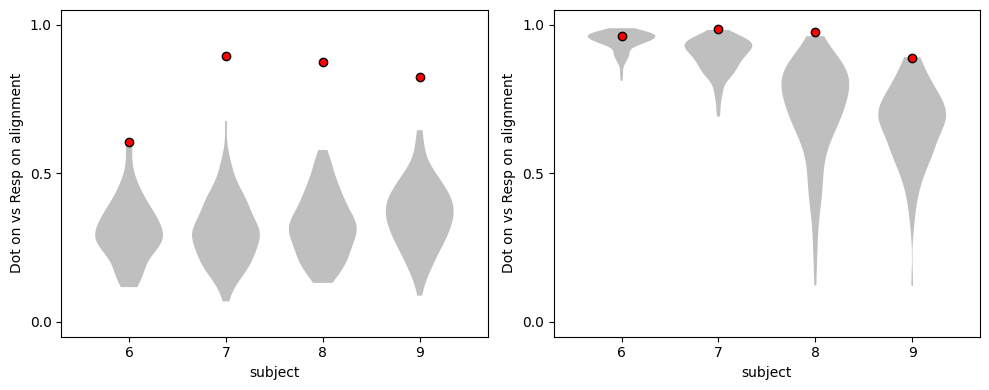

In [130]:
AX_NAMES = ['source', 'target']

subj = list(epoch_orientation)
x = np.arange(len(subj))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for k, ax in enumerate(axes):
    null_k = [epoch_orientation[s][1][:, k] for s in subj]
    obs_k  = [epoch_orientation[s][0][k]    for s in subj]

    vp = ax.violinplot(null_k, positions=x, widths=0.7, showextrema=False)
    for body in vp['bodies']:
        body.set_facecolor('grey')
        body.set_edgecolor('none')
        body.set_alpha(0.5)
    ax.plot(x, obs_k, 'o', markersize=6, markerfacecolor='red', markeredgecolor='k')

    ax.set_xticks(x, [str(s) for s in subj])
    ax.set_xlim([-0.7, len(subj) - 0.3])
    ax.set_yticks([0, 0.5, 1])
    ax.set_ylim([-0.05, 1.05])
    ax.set_xlabel('subject')
    ax.set_ylabel('Dot on vs Resp on alignment')

fig.tight_layout()
fig.savefig(FIG_DIR/'FigureS3C.png', dpi=300)
plt.show()

## 5. Communication-related PC loadings and specificity test (Fig. S4B-C)

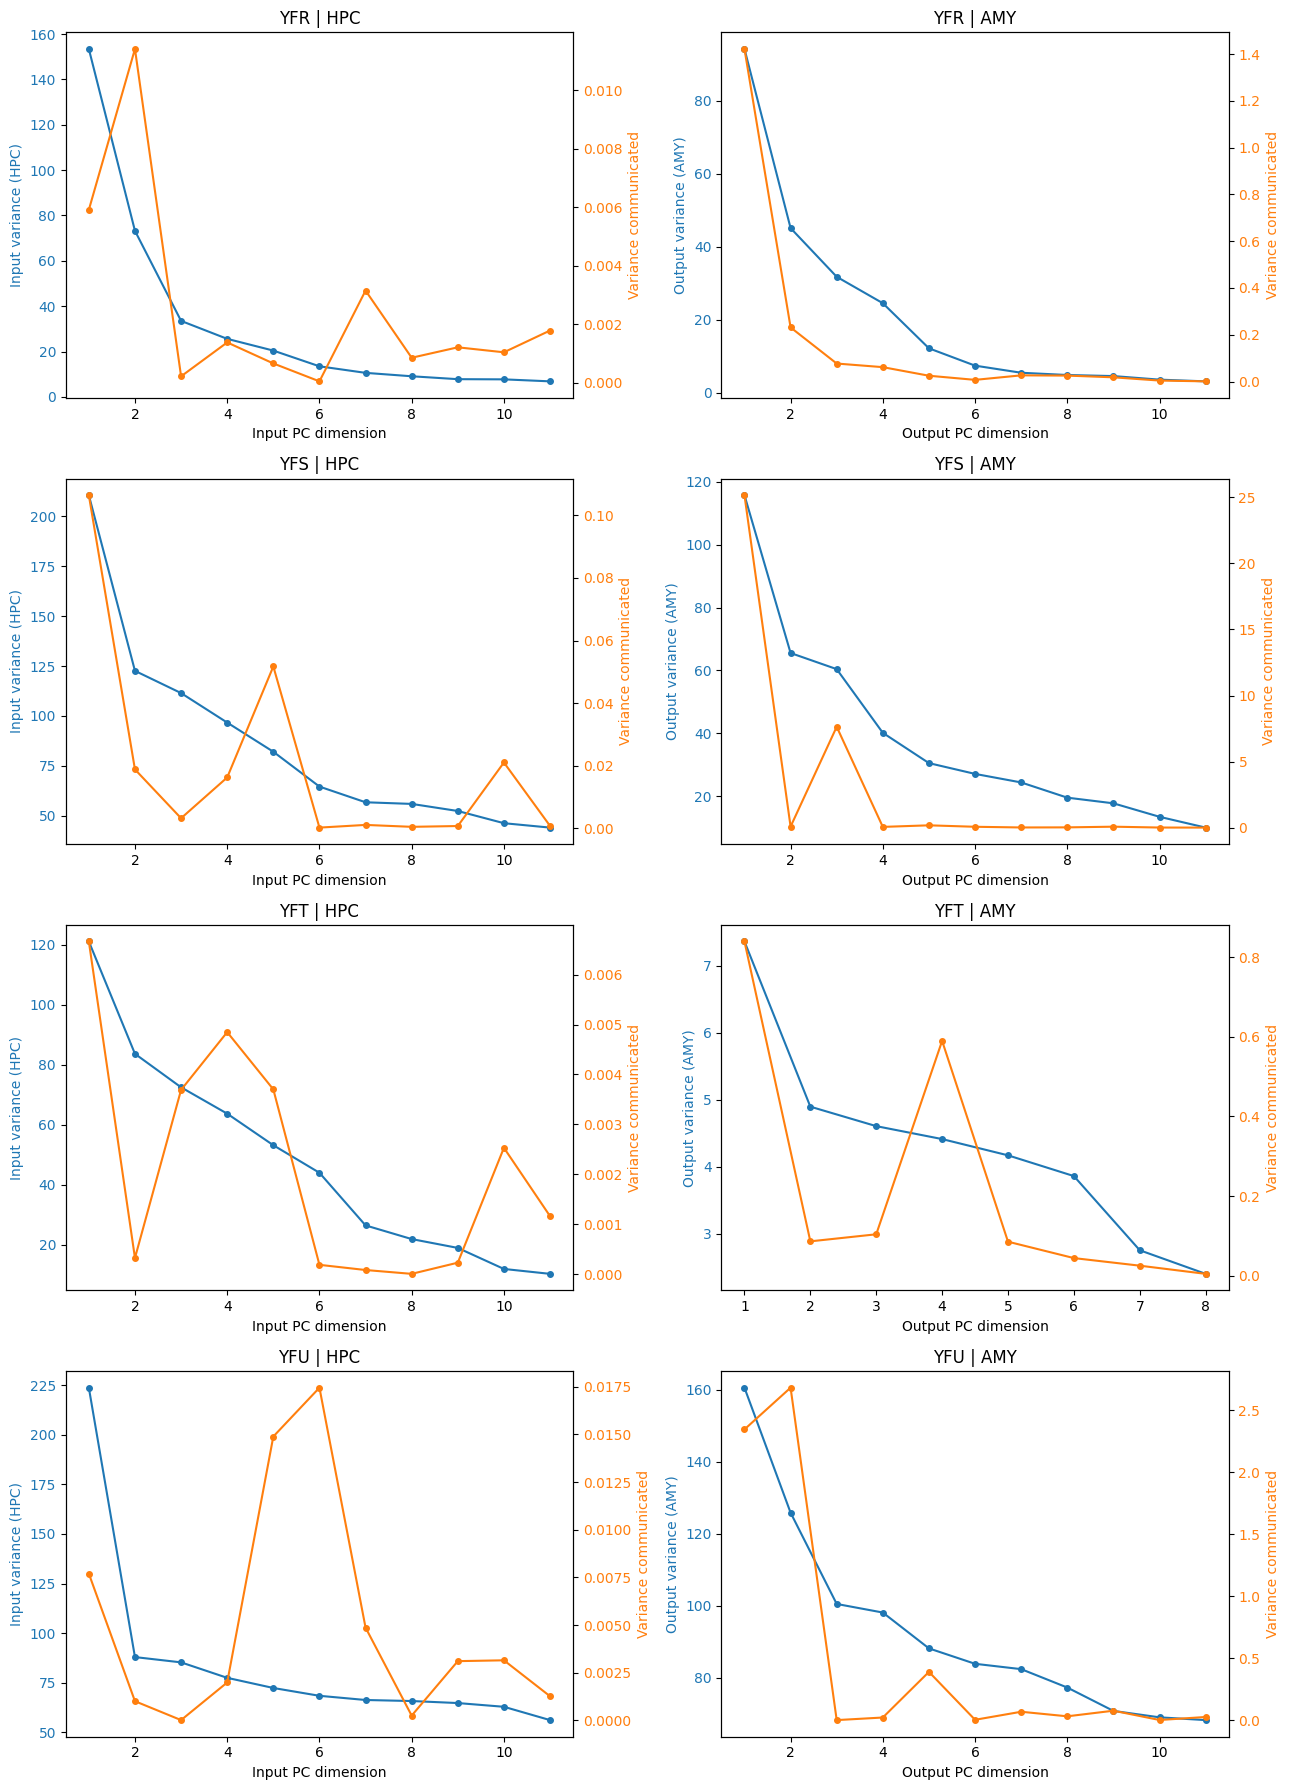

In [125]:
pc_details=[]
for i,s in enumerate(CS_SUBJECT_INDICES):
    X,Y=cs_residuals[s]
    x=X.reshape(-1,X.shape[-1]); x=x-x.mean(0)
    y=Y.reshape(-1,Y.shape[-1]); y=y-y.mean(0)
    W=models_rrr[i][0]
    Sigma_x=x.T@x/len(x); Sigma_y=y.T@y/len(y)
    lx,Vx=eigh(Sigma_x); ly,Vy=eigh(Sigma_y)
    lx=np.maximum(lx[::-1],0);ly=np.maximum(ly[::-1],0)
    Vx=Vx[:,::-1];Vy=Vy[:,::-1]
    comm_x=np.diag(Vx.T@W@W.T@Vx)
    comm_y=np.diag(Vy.T@(W.T@Sigma_x@W)@Vy)
    pc_details.append(dict(lx=lx,ly=ly,Vx=Vx,Vy=Vy,comm_x=comm_x,comm_y=comm_y))

fig,axes=plt.subplots(4,2,figsize=(13,18))
for i,(name,entry) in enumerate(zip(CS_NAMES,pc_details)):
    for col,(variance,load,region) in enumerate([(entry['lx'],entry['comm_x'],'HPC'),
                                                 (entry['ly'],entry['comm_y'],'AMY')]):
        ax=axes[i,col]
        n=min(11,len(variance))
        x_axis=np.arange(1,n+1)
        color_pc='tab:blue'
        color_comm='tab:orange'
        ax.plot(x_axis,variance[:n],'o-',color=color_pc,markersize=4)
        ax.set_xlabel('Input PC dimension' if col==0 else 'Output PC dimension')
        ax.set_ylabel(f'Input variance ({region})' if col==0 else f'Output variance ({region})',color=color_pc)
        ax.tick_params(axis='y',labelcolor=color_pc)
        twin=ax.twinx()
        twin.plot(x_axis,load[:n],'o-',color=color_comm,markersize=4)
        twin.set_ylabel('Variance communicated',color=color_comm)
        twin.tick_params(axis='y',labelcolor=color_comm)
        ax.set_title(f'{name} | {region}')
fig.tight_layout()
fig.savefig(FIG_DIR/'FigureS4B.png',dpi=300)
plt.show()


In [ ]:
ALIGNED_PC_X=[[0,1],[0,4],[0,3],[4,5]]
ALIGNED_PC_Y=[[0,1],[0,2],[0,3],[0,1]]
COMPARISON_PC_X=[[2,3],[1,2],[1,2],[0,1]]
COMPARISON_PC_Y=[[2,3],[1,3],[1,2],[2,3]]

pc_projection={'aligned':{'HPC':[],'AMY':[]},'comparison':{'HPC':[],'AMY':[]}}
for i,s in enumerate(CS_SUBJECT_INDICES):
    mean_h,mean_a=mean_pair(s)
    entry=pc_details[i]
    for kind,ix,iy in [('aligned',ALIGNED_PC_X[i],ALIGNED_PC_Y[i]),
                       ('comparison',COMPARISON_PC_X[i],COMPARISON_PC_Y[i])]:
        pc_projection[kind]['HPC'].append(mean_h@entry['Vx'][:,ix])
        pc_projection[kind]['AMY'].append(mean_a@entry['Vy'][:,iy])

observed_pc={}
for kind in pc_projection:
    observed_pc[kind]={reg:np.array([r2_subspace(p,labels)[0] for p in pc_projection[kind][reg]])
                       for reg in ['HPC','AMY']}

rng=np.random.default_rng(SEED)
null_pc_diff={reg:np.empty((N_PC_PERM,100)) for reg in ['HPC','AMY']}
for b in range(N_PC_PERM):
    shuffled=rng.permutation(labels)  # paired permutation for aligned and comparison
    for reg in ['HPC','AMY']:
        al=np.mean([r2_subspace(p,shuffled)[0] for p in pc_projection['aligned'][reg]],axis=0)
        co=np.mean([r2_subspace(p,shuffled)[0] for p in pc_projection['comparison'][reg]],axis=0)
        null_pc_diff[reg][b]=al-co

p_pc_diff={}
for reg in ['HPC','AMY']:
    diff=(observed_pc['aligned'][reg]-observed_pc['comparison'][reg]).mean(0)
    p_pc_diff[reg]=(np.sum(null_pc_diff[reg]>=diff[None,:],axis=0)+1)/(N_PC_PERM+1)


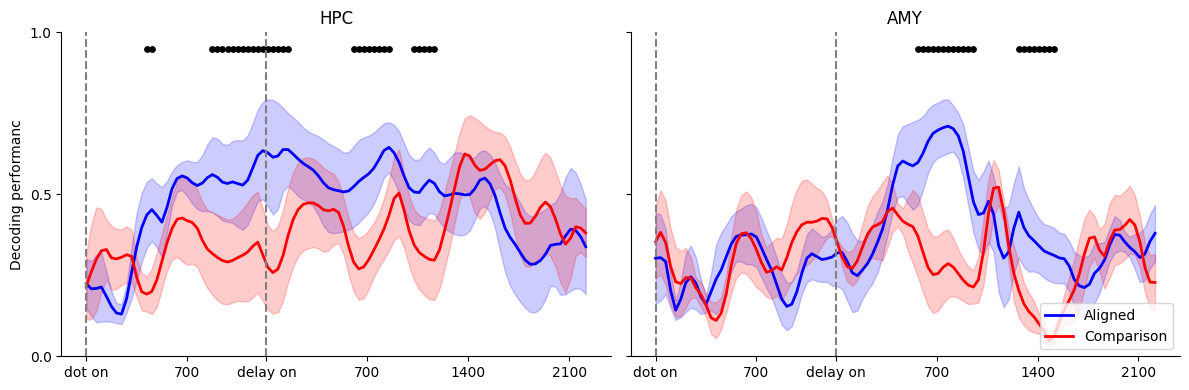

In [126]:
fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax,reg in zip(axes,['HPC','AMY']):
    x=np.arange(N_BINS)*BIN_MS
    for kind,color in [('aligned','b'),('comparison','r')]:
        r=observed_pc[kind][reg]
        avg=r.mean(0);sem=r.std(0)/np.sqrt(len(r))
        ax.plot(x,avg,color=color,linewidth=2,label=kind.title())
        ax.fill_between(x,avg-sem,avg+sem,color=color,alpha=0.2)
    ax.scatter(x[p_pc_diff[reg]<.05],np.full(np.sum(p_pc_diff[reg]<.05),.95),color='k',s=15)
    ax.set_xticks([0,700,1250,1950,2650,3350],
                  ['dot on',700,'delay on',700,1400,2100])
    ax.vlines([0,1250],0,1,color='grey',linestyle='--')
    ax.set_yticks([0,0.5,1])
    ax.set_ylim([0,1])
    ax.set_title(reg)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
axes[0].set_ylabel('Decoding performanc')
axes[1].legend(loc='lower right')
fig.tight_layout()
fig.savefig(FIG_DIR/'FigureS4C.png',dpi=300)
plt.show()

## 6. Lagged correlation of numerosity time courses (Fig. S4A)

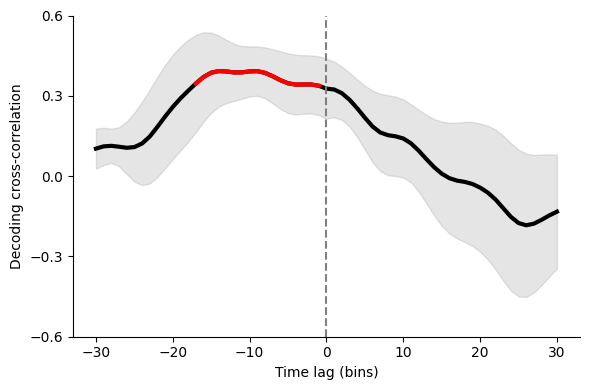

In [127]:
lags=np.arange(-30,31)
per_subject=[]
for i in range(4):
    x=observed_hpc[i];y=observed_amy[i]
    corr=[]
    for lag in lags:
        if lag<0:
            a=x[:lag];b=y[-lag:]
        elif lag>0:
            a=x[lag:];b=y[:-lag]
        else:
            a=x;b=y
        corr.append(pearsonr(a,b)[0])
    per_subject.append(corr)
per_subject=np.asarray(per_subject)
fig,ax=plt.subplots(figsize=(6,4))
mean_corr=per_subject.mean(0)
ax.plot(lags,mean_corr,color='k',linewidth=3)
above_avg=np.where(mean_corr>mean_corr[lags.tolist().index(0)])[0]
ax.plot(lags[above_avg],mean_corr[above_avg],color='r',linewidth=3)
ax.fill_between(lags,mean_corr-per_subject.std(0)/np.sqrt(4),
                    mean_corr+per_subject.std(0)/np.sqrt(4),color='grey',alpha=0.2)
ax.vlines(0,-0.6,0.6,color='grey',linestyle='--')
ax.set_xticks([-30,-20,-10,0,10,20,30])
ax.set_yticks([-0.6,-0.3,0,0.3,0.6])
ax.set_ylim([-0.6,0.6])
ax.set_xlabel('Time lag (bins)')
ax.set_ylabel('Decoding cross-correlation')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR/'FigureS4A.png',dpi=300)
plt.show()